In [ ]:
!cp -r /content/drive/MyDrive/deep-past-initiative-machine-translation.zip  /content/deep-past-initiative-machine-translation.zip

In [ ]:
!unzip /content/deep-past-initiative-machine-translation.zip

Archive:  /content/deep-past-initiative-machine-translation.zip
  inflating: OA_Lexicon_eBL.csv      
  inflating: Sentences_Oare_FirstWord_LinNum.csv  
  inflating: bibliography.csv        
  inflating: eBL_Dictionary.csv      
  inflating: publications.csv        
  inflating: published_texts.csv     
  inflating: resources.csv           
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
import pandas as pd

tr = pd.read_csv('/content/train.csv')
tr['text_combined'] = tr['translation']+''+tr['transliteration']
print(tr['translation'].dropna().str.len().max())
print(tr['transliteration'].dropna().str.len().max())
print(tr['text_combined'].dropna().str.len().max())


3895
932
4787


In [ ]:
df = tr[
    (tr['transliteration'].str.len() <= 640) &
    (tr['translation'].str.len() <= 768)
]

print(df.shape)

(1169, 4)


In [ ]:
tr.shape

(1561, 4)

In [ ]:
tr.columns

Index(['oare_id', 'transliteration', 'translation'], dtype='object')

In [ ]:
translation_max  = tr.loc[tr['translation'].str.len().idxmax(), 'translation']
transliteration_max  = tr.loc[tr['transliteration'].str.len().idxmax(), 'transliteration']

print(translation_max)
print(transliteration_max)

As to the 4 minas of silver that Enna-Suen owed to our father, 2.5 minas of silver, interest, 0.5 mina, expenses on the 5 minas of silver, I received from Enna-Suen. 1 mina of silver furthermore that Ennam-Adad owed I received at the same time from Enna-Suen. When I wrote to Warad-ilī in Kuburnat and ... When I wrote to Katila(?) to Amur-... and ... 4 shekels of silver ... x mina silver ... Šad-ahšu ... 1 mina 5 shekels of silver owed by ...; 0.3333 mina of silver owed by ... x mina of silver ... I received  from the man of Tumliya; 1 mina of silver owed by Ušhata's son; 2.5 mina of silver owed by Ikūn-pīya son of ...; 1 talent of -copper owed by Shorty"; also Shorty gave me a slave-girl and left her with Ah-šalim. I have not yet received Šimašitiša. In all: 30 minas 3 shekels of silver apart from the copper I received from the oustanding claims of my father. 6 minas 15 shekels ... the previous ... 0.5 ... I paid to the office of the colony; 1.5 mina of refined silver under my seal, 10

Loading datasets...

Train dataset shape: (1561, 3)
Test dataset shape: (4, 5)

Train columns: ['oare_id', 'transliteration', 'translation']

Sample training data:
                                oare_id  \
0  004a7dbd-57ce-46f8-9691-409be61c676e   
1  0064939c-59b9-4448-a63d-34612af0a1b5   
2  0073f2c0-524c-4bbf-915a-8c1772a4fb98   

                                     transliteration  \
0  KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-(d)IM KIŠI...   
1               1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé   
2  TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Loading MADLAD400 tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   265.07
  Median: 228.00
  Std:    165.97
  Min:    17
  Max:    635
  75th percentile: 393
  90th percentile: 540
  95th percentile: 553
  99th percentile: 580

📊 TARGET (Translation) Token Lengths:
  Mean:   157.85
  Median: 123.00
  Std:    144.43
  Min:    4
  Max:    1267
  75th percentile: 211
  90th percentile: 317
  95th percentile: 415
  99th percentile: 717

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 553
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 717
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 540
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile

/tmp/ipython-input-1631029989.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


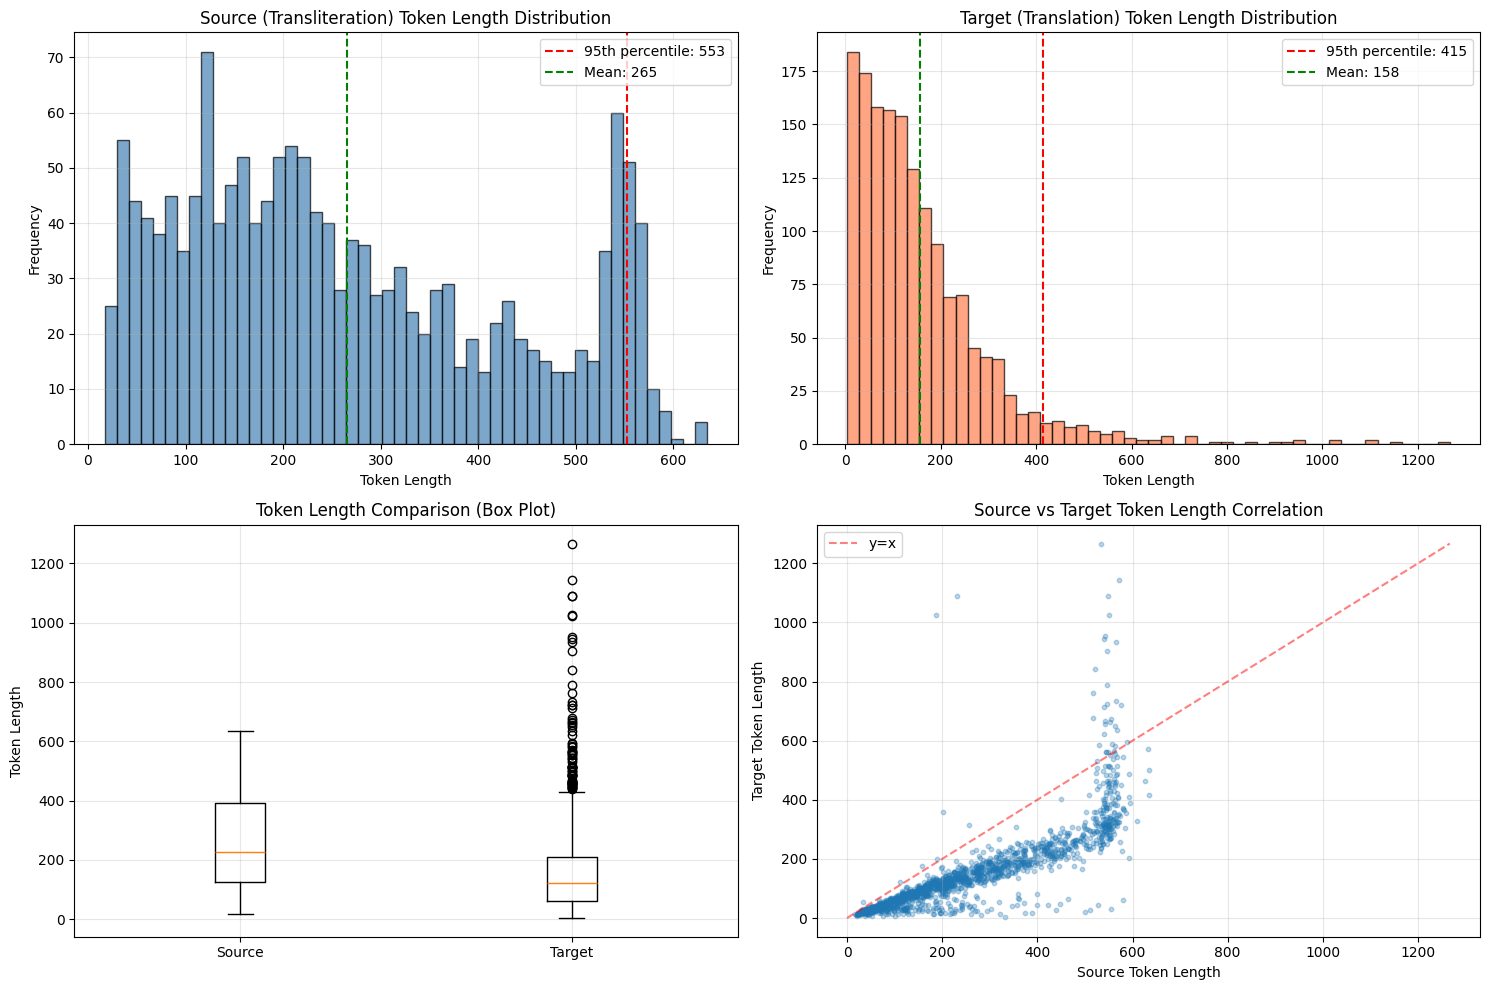


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 553 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ⚠️  Consider adjusting based on your data

3. Samples that will be truncated at 512 tokens:
   - Source: 222 samples (14.22%)
   - Target: 44 samples (2.82%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.2 MB/s eta 0:00:00


In [ ]:
!pip install sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 8.1 MB/s eta 0:00:00


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 3
    LEARNING_RATE = 1e-4
    OUTPUT_DIR = "./madlad400-3b-akkadian"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")


def simple_sentence_aligner(df):
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)


# ==========================================
# Tokenization & preprocessing
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # FIX 1: Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    # FIX 2: Replace invalid tokens with pad token
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        # Fallback: decode one by one and skip problematic sequences
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")  # Empty string for failed decoding

    # Process labels
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",  # Changed to save checkpoints
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,

    # FIX 3: Add generation config to prevent overflow
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,

    logging_steps=10,
    report_to="none",

    greater_is_better=True,
    load_best_model_at_end=True,
    metric_for_best_model="chrf",

    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,  # FIX 4: Use processing_class instead of tokenizer
    compute_metrics=compute_metrics
)

print("Starting Training with MADLAD400-3B-MT (FP32 mode)...")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")

Expanded Train Data: 1561 sentences (Alignment applied)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Training with MADLAD400-3B-MT (FP32 mode)...


Epoch,Training Loss,Validation Loss,Chrf
1,1.319700,1.297073,34.797976
2,0.892500,1.037243,48.393850
3,0.718000,1.013998,48.321484


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Model saved to ./madlad400-3b-akkadian


In [ ]:
!cp -r /content/madlad400-3b-akkadian/checkpoint-702/  /content/checkpoint-702/

In [ ]:
!rm /content/checkpoint-702/optimizer.pt

# this gave me 30.04 score

# retrain the model with different processing

In [ ]:
import kagglehub
import os

# 1. Manually set your credentials (most reliable method)
os.environ['KAGGLE_USERNAME'] = "ravikshdikola"  # Check your kaggle.json
os.environ['KAGGLE_KEY'] = "apply token here"

# Download latest version
path = kagglehub.dataset_download("ravikshdikola/dpc2-exp2")

print("Path to dataset files:", path)

100%|██████████| 10.2G/10.2G [04:50<00:00, 37.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1


In [ ]:
!cp -r /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1   /content/dpc2-exp2/

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576
    BATCH_SIZE = 1
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


# args = Seq2SeqTrainingArguments(
#     output_dir=Config.OUTPUT_DIR,
#     eval_strategy="no",
#     save_strategy="epoch",
#     learning_rate=Config.LEARNING_RATE,

#     fp16=False,
#     per_device_train_batch_size=1,
#     per_device_eval_batch_size=1,
#     gradient_accumulation_steps=4,

#     weight_decay=0.01,
#     save_total_limit=2,
#     num_train_epochs=Config.EPOCHS,
#     predict_with_generate=False,

#     generation_max_length=Config.MAX_LENGTH,
#     generation_num_beams=4,

#     logging_steps=10,
#     report_to="none",

#     greater_is_better=True,
#     load_best_model_at_end=True,
#     metric_for_best_model="chrf",

#     lr_scheduler_type="cosine",
#     warmup_steps=50,  # Reduced warmup for 1 epoch
#     max_grad_norm=1.0,
# )

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,
    logging_steps=10,
    report_to="none",
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("Starting Training with pretrained MADLAD400-3B-MT...")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"Max Length: {Config.MAX_LENGTH}")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")



Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting Training with pretrained MADLAD400-3B-MT...
Learning Rate: 5e-05
Epochs: 1
Max Length: 576


Step,Training Loss
10,0.950200
20,0.992700
30,0.834800
40,0.846800
50,0.873400
60,0.820900
70,0.758700
80,0.856600
90,0.781800
100,0.897800


Model saved to ./madlad400-3b-akkadian-final


# this actuall improve my score to 31.50

# now again experiment with different max_length=732

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 732  # Updated from 576
    BATCH_SIZE = 1  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 8  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 732
Batch Size: 1
Gradient Accumulation Steps: 8
Effective Batch Size: 8
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,1.003700
20,0.907200
30,0.912800
40,0.819700
50,0.840500
60,0.751900
70,0.813700
80,0.672800
90,0.766300
100,0.871300



✓ Model saved to ./madlad400-3b-akkadian-final


# this improve my score to 31.80

# now i am testing it 1080

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 1080  # Updated to 1080
    BATCH_SIZE = 1  # Keep at 1 for FP32 with longer sequences
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings for 1080 tokens with FP32
    GRADIENT_ACCUMULATION_STEPS = 16  # Increased to maintain effective batch size
    USE_GRADIENT_CHECKPOINTING = True  # Essential for longer sequences
    FP16 = False  # Using FP32 for full precision

    # Additional memory optimizations
    DATALOADER_NUM_WORKERS = 0  # Reduce to 0 to save memory with longer sequences
    DATALOADER_PIN_MEMORY = False  # Disable to save memory


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
# Aggressive memory cleanup before loading model
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

print("Loading model in FP32...")
model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32,  # FP32 for full precision
    low_cpu_mem_usage=True  # Enable memory-efficient loading
)

# Enable gradient checkpointing - CRITICAL for 1080 sequence length
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

# Additional memory optimization: reduce cache size if model supports it
if hasattr(model.config, 'use_cache'):
    model.config.use_cache = False
    print("✓ Model cache disabled during training")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings for 1080 sequence length
    fp16=Config.FP16,  # False - using FP32
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management optimized for longer sequences
    dataloader_pin_memory=Config.DATALOADER_PIN_MEMORY,
    dataloader_num_workers=Config.DATALOADER_NUM_WORKERS,

    # Disable some features to save memory
    load_best_model_at_end=False,
    metric_for_best_model=None,

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH,

    # Additional memory optimizations
    ddp_find_unused_parameters=False,
    save_safetensors=True,  # Use safetensors for more efficient saving
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16} (Using FP32)")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print(f"Memory Optimizations: Enabled")
print("=" * 60)

# Monitor memory before training
if torch.cuda.is_available():
    print(f"GPU Memory before training: {torch.cuda.memory_allocated() / 1024**3:.2f} GB allocated")
    print(f"GPU Memory reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

# Final memory stats
if torch.cuda.is_available():
    print(f"\nFinal GPU Memory: {torch.cuda.memory_allocated() / 1024**3:.2f} GB allocated")
    print(f"Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading model in FP32...


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (3 outputs left out)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting Training with pretrained MADLAD400-3B-MT
Max Length: 1080
Batch Size: 1
Gradient Accumulation Steps: 16
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False (Using FP32)
Gradient Checkpointing: True
Available VRAM: 80GB
Memory Optimizations: Enabled
GPU Memory before training: 10.95 GB allocated
GPU Memory reserved: 10.96 GB


Step,Training Loss
10,0.980600
20,0.919700
30,0.833600
40,0.781100
50,0.835300
60,0.834400
70,0.768200
80,0.840000
90,0.818300



✓ Model saved to ./madlad400-3b-akkadian-final

Final GPU Memory: 32.88 GB allocated
Peak GPU Memory: 54.82 GB


# this degrade score to 31.20

In [ ]:
# !rm -r /content/madlad400-3b-akkadian-final

rm: cannot remove '/content/madlad400-3b-akkadian-final': No such file or directory


In [ ]:
!rm -r /content/kaggle.json

rm: cannot remove '/content/kaggle.json': No such file or directory


In [ ]:
%%writefile kaggle.json
{
"username":"ravikshdikola","key":"apply token here"
}


Writing kaggle.json


In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-3608/optimizer.pt

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
%cd /content/madlad400-3b-akkadian-final/checkpoint-8914/


/content/madlad400-3b-akkadian-final/checkpoint-8914


In [ ]:
%%writefile dataset-metadata.json
{
  "title": "madlab Akkadian retrained_1st_stage_3mix",
  "id": "ravikshdikola/madlab-akkadian-retrained-1st-stage-3mix",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}


Writing dataset-metadata.json


In [ ]:
!kaggle datasets create -p .

Starting upload for file tokenizer_config.json
100% 379/379 [00:00<00:00, 494B/s]
Upload successful: tokenizer_config.json (379B)
Starting upload for file training_args.bin
100% 5.20k/5.20k [00:00<00:00, 7.04kB/s]
Upload successful: training_args.bin (5KB)
Starting upload for file generation_config.json
100% 121/121 [00:00<00:00, 154B/s]
Upload successful: generation_config.json (121B)
Starting upload for file model.safetensors
100% 11.0G/11.0G [08:02<00:00, 24.4MB/s]
Upload successful: model.safetensors (11GB)
Starting upload for file rng_state.pth
100% 14.3k/14.3k [00:00<00:00, 19.8kB/s]
Upload successful: rng_state.pth (14KB)
Starting upload for file tokenizer.json
100% 15.8M/15.8M [00:02<00:00, 5.97MB/s]
Upload successful: tokenizer.json (16MB)
Starting upload for file trainer_state.json
100% 162k/162k [00:01<00:00, 136kB/s]
Upload successful: trainer_state.json (162KB)
Starting upload for file config.json
100% 854/854 [00:00<00:00, 1.08kB/s]
Upload successful: config.json (854B)
S

#lets add new dataset and tried to analyze it and do finetuning

In [ ]:
import pandas as pd
from datasets import load_dataset

# Load the dataset
ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)

train = pd.read_csv('/content/train.csv')
train = train.drop(['oare_id'],axis=1)

final_train = pd.concat([df,train])
# frac=1 means "return 100% of the data"
# random_state=42 ensures you get the same shuffle every time you run it
final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
final_train.to_csv('/content/final_train.csv',index=False)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2870 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2812 [00:00<?, ? examples/s]

Loading datasets...

Train dataset shape: (57721, 2)
Test dataset shape: (4, 5)

Train columns: ['translation', 'transliteration']

Sample training data:
                                         translation  \
0                    in the possession of the priest   
1  They are waiting for their ... s, their houses...   
2                              which in their hands    

                                     transliteration  
0                             ŠU.2 ša {LU₂~v}-SANGA   
1  ina IGI ... ni-šu₂-nu E₂-MEŠ-šu₂-nu ... šu₂-nu...  
2                               ša₂ ina ŠU.2-šu₂-nu   

Loading MADLAD400 tokenizer...


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   57.14
  Median: 27.00
  Std:    80.43
  Min:    5
  Max:    1744
  75th percentile: 63
  90th percentile: 137
  95th percentile: 210
  99th percentile: 426

📊 TARGET (Translation) Token Lengths:
  Mean:   30.83
  Median: 14.00
  Std:    49.44
  Min:    2
  Max:    1267
  75th percentile: 34
  90th percentile: 71
  95th percentile: 113
  99th percentile: 238

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 210
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 426
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 137
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile (210 tok

/tmp/ipython-input-218279686.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


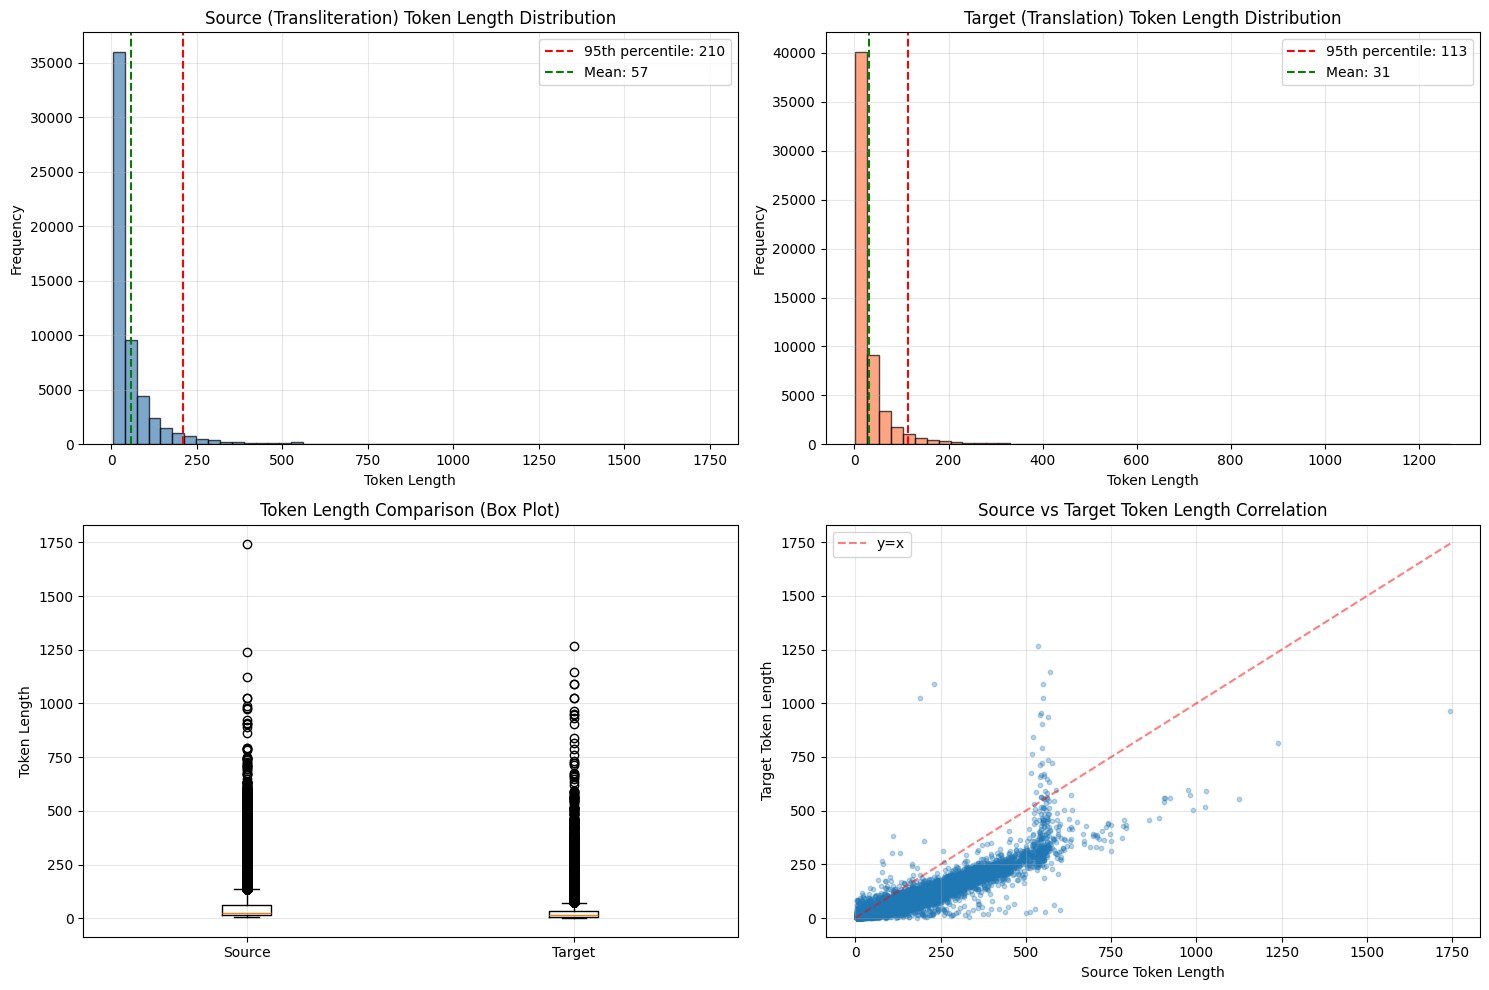


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 210 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ✅ This is sufficient!

3. Samples that will be truncated at 512 tokens:
   - Source: 332 samples (0.58%)
   - Target: 55 samples (0.10%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/final_train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=200,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=3,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 57721 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/57721 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (2 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 576
Batch Size: 4
Gradient Accumulation Steps: 4
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.816300
20,3.609200
30,3.361900
40,3.032200
50,2.936600
60,2.854800
70,2.847100
80,2.686000
90,2.676000
100,2.643900



✓ Model saved to ./madlad400-3b-akkadian-final


# score of 34.5

# lets just take more mixture of dataset

In [ ]:
import pandas as pd
from datasets import load_dataset

tr = pd.read_csv('/content/train.csv')
tr = tr.drop(['oare_id'],axis=1)

ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)

ds1 = load_dataset("phucthaiv02/akkadian_english_sentences_alignment_2")
df1 = pd.DataFrame(ds1['train'])

ds2 = load_dataset("phucthaiv02/akkadian-translation")
df_train_2 = pd.DataFrame(ds2['train'])
df_val_2 = pd.DataFrame(ds2['validation'])
df2 = pd.concat([df_train_2, df_val_2])
df2 = df2.drop(['pdf_name','page'],axis=1)


f_df = pd.concat([df,df1,df2])

final_train = pd.concat([f_df,tr])
final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
final_train.to_csv('/content/final_train.csv',index=False)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

... (6 outputs left out)

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.28M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/768k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/72653 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1561 [00:00<?, ? examples/s]

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 8e-5 # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=4457,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 142612 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/142612 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/742 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


... (5 outputs left out)

Step,Training Loss
10,47.960452
20,47.861609
30,47.771146
40,47.527783
50,47.157611
60,46.730692
70,46.352277
80,45.904562
90,45.801898
100,45.443491


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✓ Model saved to ./madlad400-3b-akkadian-final


# dataset becomes to huge and it worsen the result a lot

In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-4457/

In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-8914/optimizer.pt

#lets take mixture model and train it on train dataset

In [ ]:
import kagglehub
import os

# 1. Manually set your credentials (most reliable method)
os.environ['KAGGLE_USERNAME'] = "ravikshdikola"  # Check your kaggle.json
os.environ['KAGGLE_KEY'] = "apply token here"



# Download latest version
path = kagglehub.dataset_download("ravikshdikola/madlab-akkadian-retrained-1st-stage-3mix")

print("Path to dataset files:", path)

100%|██████████| 10.2G/10.2G [06:57<00:00, 26.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ravikshdikola/madlab-akkadian-retrained-1st-stage-3mix/versions/1


In [ ]:
!cp -r /root/.cache/kagglehub/datasets/ravikshdikola/madlab-akkadian-retrained-1st-stage-3mix/versions/1   /content/dpc2-exp2/

In [ ]:
# import pandas as pd
# from datasets import load_dataset

# tr = pd.read_csv('/content/train.csv')
# tr = tr.drop(['oare_id'],axis=1)

# ds = load_dataset("cipher-ling/akkadian")
# # This takes the list of dictionaries and turns keys into column headers
# df_train = pd.DataFrame(ds['train']['translation'])
# df_val = pd.DataFrame(ds['validation']['translation'])
# df_test = pd.DataFrame(ds['test']['translation'])

# df = pd.concat([df_train, df_val, df_test])
# df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
# df = df.drop(['ak'],axis=1)



# ds2 = load_dataset("phucthaiv02/akkadian-translation")
# df_train_2 = pd.DataFrame(ds2['train'])
# df_val_2 = pd.DataFrame(ds2['validation'])
# df2 = pd.concat([df_train_2, df_val_2])
# df2 = df2.drop(['pdf_name','page'],axis=1)


# f_df = pd.concat([df,df2])

# final_train = pd.concat([f_df,tr])
# final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
# final_train.to_csv('/content/final_train.csv',index=False)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

... (3 outputs left out)

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.28M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/768k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/72653 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1561 [00:00<?, ? examples/s]

In [ ]:
import os
os.environ["HF_TOKEN"] = "apply token here"


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 6e-5 # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=100,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 1561 sentences


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/742 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


✓ Gradient checkpointing enabled for memory efficiency


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Starting Training with pretrained MADLAD400-3B-MT
Max Length: 576
Batch Size: 4
Gradient Accumulation Steps: 4
Effective Batch Size: 16
Learning Rate: 6e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


Step,Training Loss
10,12.630650
20,12.816481
